# M03-1 | Why Observers Appear Where They Do: Annotations, Quantizer, prepare_pt2e

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m03_quantizer_api/01_annotate_then_prepare.ipynb)

In M02 we inserted observers by hand, copying the positions straight from XNNPACKQuantizer. This chapter answers: who decides where `prepare_pt2e` inserts observers?

The one-line answer: **someone attached an annotation at that position, and `prepare_pt2e` simply inserts an observer wherever there is one.**

Three roles are involved:

| Role | What it is | What it does |
|---|---|---|
| `QuantizationAnnotation` | The annotation, stored in `node.meta["quantization_annotation"]` | Records which input edges of this node, or its output, are to be quantized |
| `Quantizer.annotate` | The one who attaches annotations, implemented by the backend author | Decides which positions are quantized and with what spec |
| `prepare_pt2e` | The one who reads annotations | Inserts one observer at every annotated position, and does nothing where there is none |

This notebook uses no ready-made quantizer; everything is written by hand:

- **A.** What an annotation looks like: attach two annotations ourselves.
- **B.** How the three roles divide the work: write a minimal Quantizer, add annotations one at a time, and watch observers grow one by one.
- **C.** Edge annotations vs. output annotations: what differs when one tensor has two users.


In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import the course's common/
    os.chdir(f"{repo}/en/m03_quantizer_api")

In [2]:
import copy

import torch

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    MinMaxObserver,
    QuantizationAnnotation,
    QuantizationSpec,
    Quantizer,
    export_module,
    prepare_pt2e,
    quiet,
)
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

A `QuantizationSpec` answers "how should this position be quantized": dtype, integer range, scheme, and which observer collects the statistics.
All annotations in this notebook use the same one:


In [3]:
SPEC = QuantizationSpec(
    dtype=torch.int8,
    quant_min=-128,
    quant_max=127,
    qscheme=torch.per_tensor_affine,
    observer_or_fake_quant_ctr=MinMaxObserver,
)

## A. What an Annotation Looks Like

`QuantizationAnnotation` has two fields, one for each kind of position:

- `input_qspec_map`: `{upstream node: spec}`. Attached to the consumer, it means the **edge** "upstream → this node" is quantized. Note that the key is the upstream producer, not the consumer itself.
- `output_qspec`: the **output** of this node is quantized.

On the small conv → relu model, attach two: the edge `x → conv2d`, and the output of relu.


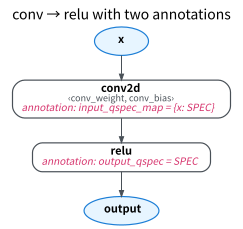

In [4]:
gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
nodes = {n.name: n for n in gm.graph.nodes}  # find nodes by name: x, conv_weight, conv2d, relu...

nodes["conv2d"].meta[ANNOTATION_KEY] = QuantizationAnnotation(input_qspec_map={nodes["x"]: SPEC})  # pyright: ignore[reportCallIssue]
nodes["relu"].meta[ANNOTATION_KEY] = QuantizationAnnotation(output_qspec=SPEC)  # pyright: ignore[reportCallIssue]

draw(gm, notes={"conv2d": "annotation: input_qspec_map = {x: SPEC}", "relu": "annotation: output_qspec = SPEC"},
     title="conv → relu with two annotations")

In [5]:
print(f"Attached 2 annotations; number of observers in the graph = {len(observer_nodes(gm))}")
assert len(observer_nodes(gm)) == 0

Attached 2 annotations; number of observers in the graph = 0


An annotation is just data written into `node.meta`; the graph itself is unchanged. Who reads it and turns it into an observer?

## B. How the Three Roles Divide the Work

Write a minimal Quantizer: it attaches annotations according to the list passed in, without making any judgment. `Quantizer` has only two methods that must be implemented:

- `annotate(model)`: attach annotations, return the model.
- `validate(model)`: a check after annotating (nothing is checked here; its use is in M03-3).

Both methods record themselves into `calls` when called, so we can see who calls them.


In [6]:
calls = []


class LabelQuantizer(Quantizer):
    def __init__(self, labels):
        self.labels = labels  # ("out", node name) or ("edge", upstream name, consumer name)

    def annotate(self, model):
        calls.append("annotate")
        nodes = {n.name: n for n in model.graph.nodes}
        for label in self.labels:
            if label[0] == "out":
                ann = nodes[label[1]].meta.setdefault(ANNOTATION_KEY, QuantizationAnnotation())
                ann.output_qspec = SPEC
            else:
                _, producer, consumer = label
                ann = nodes[consumer].meta.setdefault(ANNOTATION_KEY, QuantizationAnnotation())
                ann.input_qspec_map[nodes[producer]] = SPEC
        return model

    def validate(self, model):
        calls.append("validate")

Start with no annotations and add one per step. Every step only calls `prepare_pt2e(copy of the graph, LabelQuantizer(labels))`:


In [7]:
gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
steps = [
    ("no annotations", []),
    ("+ output of relu", [("out", "relu")]),
    ("+ edge x → conv2d", [("out", "relu"), ("edge", "x", "conv2d")]),
    ("+ edge conv_weight → conv2d", [("out", "relu"), ("edge", "x", "conv2d"), ("edge", "conv_weight", "conv2d")]),
]
prepared, rows = [], []
for title, labels in steps:
    calls.clear()
    p = prepare_pt2e(copy.deepcopy(gm), LabelQuantizer(labels))
    prepared.append((p, title))
    rows.append([title, len(labels), len(observer_nodes(p)), " → ".join(calls)])
table(rows, ["step", "# annotations", "# observers", "prepare_pt2e called"])

step,# annotations,# observers,prepare_pt2e called
no annotations,0,0,annotate → validate
+ output of relu,1,1,annotate → validate
+ edge x → conv2d,2,2,annotate → validate
+ edge conv_weight → conv2d,3,3,annotate → validate


In [8]:
assert [r[2] for r in rows] == [0, 1, 2, 3]
assert all(r[3] == "annotate → validate" for r in rows)

- We only ever call `prepare_pt2e`; `annotate` and `validate` are called by it on our behalf: first annotate, then check, finally insert observers.
- No annotation, no observer; one more annotation, one more observer. `prepare_pt2e` itself doesn't know where to quantize; it all comes from the annotations the Quantizer attached.

In full, `prepare_pt2e` does these things in order (torchao 0.18 `quantize_pt2e.py`):

1. Fold BN into the preceding conv (M04).
2. Call `quantizer.transform_for_annotation(model)`: lets the Quantizer rewrite the graph before annotation, e.g. turn scalar constants into tensor attributes. This is an optional method; the base class by default doesn't change the graph.
3. Call `quantizer.annotate(model)`: attach annotations.
4. Call `quantizer.validate(model)`: check the annotations.
5. Insert observers according to the annotations: for each annotated position, build an observer from the spec and insert a `call_module` node (we did this by hand in M02-2).

Let's draw the graphs of the four steps (the first row is the first two steps, the second row is the last two); the green boxes are the observers newly grown in that step:


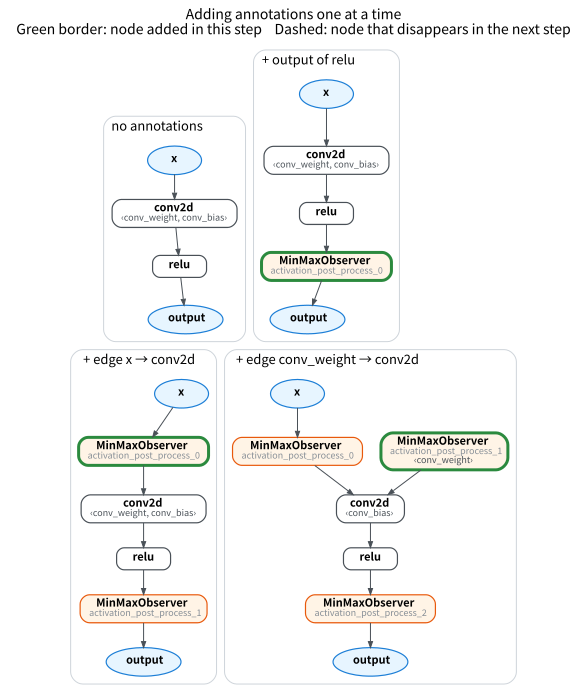

In [9]:
draw_stages(prepared, title="Adding annotations one at a time")

The output of conv2d has no annotation, so there is no observer between conv2d and relu. Whether to quantize here is entirely up to the Quantizer; M04's fusion is exactly this.
The three observers in the last step sit at the same positions as in M02-2, where we edited the graph directly without a Quantizer.

## C. Edge Annotations vs. Output Annotations

Switch to the model `cat_pool`: the input `x` feeds two convs (`conv2d`, `conv2d_1`) at once. Compare two kinds of annotation:

1. Annotate only the edge `x → conv2d` (`input_qspec_map`).
2. Annotate the output of `x` (`output_qspec`).


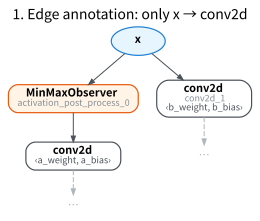

In [10]:
C_FOCUS = ["x", "activation_post_process_0", "conv2d", "conv2d_1"]  # x, observer, the two convs
gm_cat = export_module(get_model("cat_pool").eval(), example_inputs(4))
edge_only = prepare_pt2e(copy.deepcopy(gm_cat), LabelQuantizer([("edge", "x", "conv2d")]))
draw(edge_only, focus=C_FOCUS, hops=0, title="1. Edge annotation: only x → conv2d")

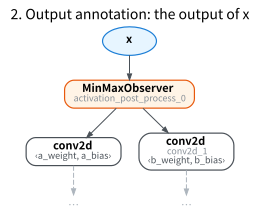

In [11]:
out_label = prepare_pt2e(copy.deepcopy(gm_cat), LabelQuantizer([("out", "x")]))
draw(out_label, focus=C_FOCUS, hops=0, title="2. Output annotation: the output of x")

In [12]:
def first_input(gm, name):
    return next(n for n in gm.graph.nodes if n.name == name).args[0]


obs_names = {n.name for n, _ in observer_nodes(edge_only)} | {n.name for n, _ in observer_nodes(out_label)}
rows = []
for label, p in [("1. edge annotation", edge_only), ("2. output annotation", out_label)]:
    for consumer in ("conv2d", "conv2d_1"):
        src = first_input(p, consumer).name
        rows.append([label, consumer, src, "quantized x" if src in obs_names else "original x"])
table(rows, ["annotation", "consumer", "input it receives", "meaning"])

annotation,consumer,input it receives,meaning
1. edge annotation,conv2d,activation_post_process_0,quantized x
1. edge annotation,conv2d_1,x,original x
2. output annotation,conv2d,activation_post_process_0,quantized x
2. output annotation,conv2d_1,activation_post_process_0,quantized x


In [13]:
assert [r[3] for r in rows] == ["quantized x", "original x", "quantized x", "quantized x"]
assert first_input(out_label, "conv2d") is first_input(out_label, "conv2d_1")  # the two convs share one observer

- An **edge annotation** only affects that one consumer: `conv2d` takes the quantized x, and `conv2d_1` takes the original x.
- An **output annotation** affects all consumers of this tensor: the two convs share one observer.

When one tensor is used by several ops, the backend can let one of them take the quantized value and another the original value, so annotations must be attachable to an "edge", not only to a node.
When the same tensor has both an edge annotation and an output annotation, neither overrides the other: if the two specs differ in attributes, the two observers are chained (quantized twice);
only when the attributes are identical do they merge into one. This is the "implicit sharing" of M03-4.

## Summary

- An annotation (`QuantizationAnnotation`) is just data in `node.meta`; attaching one doesn't change the graph.
- `prepare_pt2e` first calls `quantizer.annotate` and `quantizer.validate`, then inserts observers according to the annotations.
- `input_qspec_map` marks an edge and affects one consumer; `output_qspec` marks an output and affects all consumers.
- Hand-written annotations don't generalize to other models. M03-2 first reads the annotations XNNPACKQuantizer attaches, M03-3 switches to rules (by `node.target`) to find nodes automatically, and M03-4 handles "different positions sharing one set of scale".
